**Описание набора данных**:


Вам предоставлен анонимизированный набор данных, содержащий числовые переменные признаков, числовой целевой столбец и столбец со строковыми идентификаторами.

Задача состоит в том, чтобы предсказать значение целевого столбца в тестовом наборе данных.

**Описание файлов:**
train.csv — обучающий набор данных
test.csv — тестовый набор данных
sample_submission.csv — пример файла для отправки в правильном формате

In [1]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import random

In [2]:
import pandas as pd
import numpy as np
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
import os
print("Текущая директория:", os.getcwd())
print("Файлы в ней:", os.listdir())

Текущая директория: /kaggle/working
Файлы в ней: ['__notebook__.ipynb']


In [3]:
!kaggle competitions download -c santander-value-prediction-challenge

# Распаковка
with zipfile.ZipFile("santander-value-prediction-challenge.zip", 'r') as zip_ref:
    zip_ref.extractall(".")

print("Файлы:", os.listdir())

100%|██████████████████████████████████████| 31.5M/31.5M [00:00<00:00, 62.1MB/s]

Файлы: ['sample_submission.csv', '__notebook__.ipynb', 'santander-value-prediction-challenge.zip', 'train.csv', 'test.csv']


In [4]:
# путь к ZIP-файлу
zip_path = "santander-value-prediction-challenge.zip"
# распаковываем в текущую папку
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")  # "." означает текущую папку

# проверяем, какие файлы распаковались
print("Распакованные файлы:", os.listdir())

Распакованные файлы: ['sample_submission.csv', '__notebook__.ipynb', 'santander-value-prediction-challenge.zip', 'train.csv', 'test.csv']


## **Загрузка данных**

In [5]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

#### **Train data**

In [6]:
train_df.sample(5)

,ID,target,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37,30347e683,d08d1fbe3,6ee66e115,...,3ecc09859,9281abeea,8675bec0b,3a13ed79a,f677d4d13,71b203550,137efaa80,fb36b89d9,7e293fbaf,9fc776466
2092,7a02d3d04,2500000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.00,0,0,0,0,0,0,0
2126,7bfa3049a,1700000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.00,0,0,0,0,0,0,0
920,35b338a94,10333333.34,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.00,0,0,0,0,0,0,0
3956,e2e1b62c2,70000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,438666.66,0,0,0,0,0,0,0
3967,e36fd617f,2000000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.00,0,0,0,0,0,0,0


#### **Test data**

In [7]:
test_df.sample(5)

,ID,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37,30347e683,d08d1fbe3,6ee66e115,20aa07010,...,3ecc09859,9281abeea,8675bec0b,3a13ed79a,f677d4d13,71b203550,137efaa80,fb36b89d9,7e293fbaf,9fc776466
41232,d63dfd77b,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29137,967101685,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19316,62e9f0b8f,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
48638,fc3d9cfcb,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11741,3b84ddd6a,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,...,0.0,520000.0,0.0,0.0,0.0,0.0,0.0,400000.0,0.0,0.0


#### **Train data**

In [8]:
train_df.shape

(4459, 4993)

In [9]:
test_df.shape
# в тестовом датасете гораздо больше строк, чем в тренировачном

(49342, 4992)

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4459 entries, 0 to 4458
Columns: 4993 entries, ID to 9fc776466
dtypes: float64(1845), int64(3147), object(1)
memory usage: 169.9+ MB


In [11]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49342 entries, 0 to 49341
Columns: 4992 entries, ID to 9fc776466
dtypes: float64(4991), object(1)
memory usage: 1.8+ GB


Всего 4459 наблюдений в трейне, и 49342 в тесте. При таком количестве признаков модель очень легко переобучится. Это главная сложность соревнования.
Типы данных не соответсвуют: на трейне float, int, str, на тесте - float, str.


In [12]:
test_df.size

246315264

In [13]:
train_df.size
# разный размер

22263787

In [14]:
train_df.dtypes

ID            object
target       float64
48df886f9    float64
0deb4b6a8      int64
34b15f335    float64
              ...   
71b203550      int64
137efaa80      int64
fb36b89d9      int64
7e293fbaf      int64
9fc776466      int64
Length: 4993, dtype: object

In [15]:
test_df.dtypes

ID            object
48df886f9    float64
0deb4b6a8    float64
34b15f335    float64
a8cb14b00    float64
              ...   
71b203550    float64
137efaa80    float64
fb36b89d9    float64
7e293fbaf    float64
9fc776466    float64
Length: 4992, dtype: object

#### **Пропуски в данных**

In [16]:
train_df.isnull().sum()

ID           0
target       0
48df886f9    0
0deb4b6a8    0
34b15f335    0
            ..
71b203550    0
137efaa80    0
fb36b89d9    0
7e293fbaf    0
9fc776466    0
Length: 4993, dtype: int64

In [17]:
test_df.isnull().sum()

ID           0
48df886f9    0
0deb4b6a8    0
34b15f335    0
a8cb14b00    0
            ..
71b203550    0
137efaa80    0
fb36b89d9    0
7e293fbaf    0
9fc776466    0
Length: 4992, dtype: int64

Присутствуют константные признаки - столбцы, которые не меняются и имеют одинаковое значение для всех строк.

In [18]:
# посмотрю, сколько нулевых значений в тренировачном датасете
numeric_train = train_df.drop(['ID', 'target'], axis=1)
train_zeros = (numeric_train == 0).sum().sum()
print(f"Общее кол-во нулей на train: {train_zeros}")

numeric_test = test_df.drop('ID', axis=1)
test_zeros = (numeric_test == 0).sum().sum()
print(f"Общее кол-во нулей на test: {test_zeros}")

Общее кол-во нулей на train: 21554760
Общее кол-во нулей на test: 242805367


In [19]:
zeros_per_column = (numeric_train == 0).sum()
print(zeros_per_column[zeros_per_column > 0].sort_values(ascending=False))
print(f"Количество нулей по каждому столбцу: {zeros_per_column}")

d5308d8bc    4459
eeac16933    4459
c330f1a67    4459
9a5273600    4459
746cdb817    4459
             ... 
0572565c2    2912
c47340d97    2904
91f701ba2    2899
c5a231d81    2894
0ff32eb98    2894
Length: 4991, dtype: int64
Количество нулей по каждому столбцу: 48df886f9    4420
0deb4b6a8    4455
34b15f335    4426
a8cb14b00    4457
2f0771a37    4454
             ... 
71b203550    4424
137efaa80    4441
fb36b89d9    4425
7e293fbaf    4379
9fc776466    4296
Length: 4991, dtype: int64


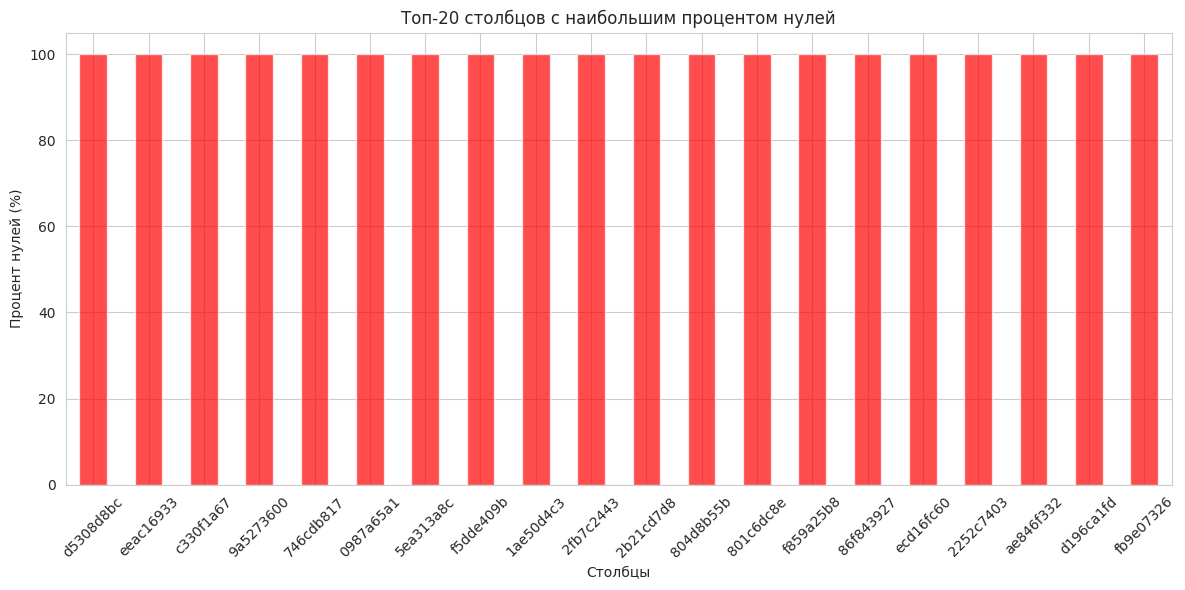

In [20]:
# Процент нулей в каждом столбце
zero_percentage = (numeric_train == 0).mean() * 100
zero_percentage = zero_percentage[zero_percentage > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
zero_percentage.head(20).plot(kind='bar', color='red', alpha=0.7)
plt.title('Топ-20 столбцов с наибольшим процентом нулей')
plt.xlabel('Столбцы')
plt.ylabel('Процент нулей (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Данные разреженные, в целом, это нормально в финансовом секторе, так как клиент может не пользоваться всеми продуктами банка, а совершать только определенные типы операций. Разреженные данные увеличивают размерность и искажают статистику.

In [21]:
# проверю нулевые значения в целевой переменной на train
target_zeros = (train_df['target'] == 0).sum()
print(f"Кол-во нулей в целевой переменной: {target_zeros} ({target_zeros/len(train_df)*100:.2f}%)")

Кол-во нулей в целевой переменной: 0 (0.00%)


In [22]:
# посмотрю дубликаты на test и train
print(f"Количество дубликатов в строках на train:{numeric_train.duplicated().sum()}")
print(f"Количество дубликатов в строках на test:{numeric_test.duplicated().sum()}")
# Константные признаки — это столбцы, которые не меняются и имеют одинаковое значение для всех строк

Количество дубликатов в строках на train:1
Количество дубликатов в строках на test:1


Статистика target:
count    4.459000e+03
mean     5.944923e+06
std      8.234312e+06
min      3.000000e+04
25%      6.000000e+05
50%      2.260000e+06
75%      8.000000e+06
max      4.000000e+07
Name: target, dtype: float64


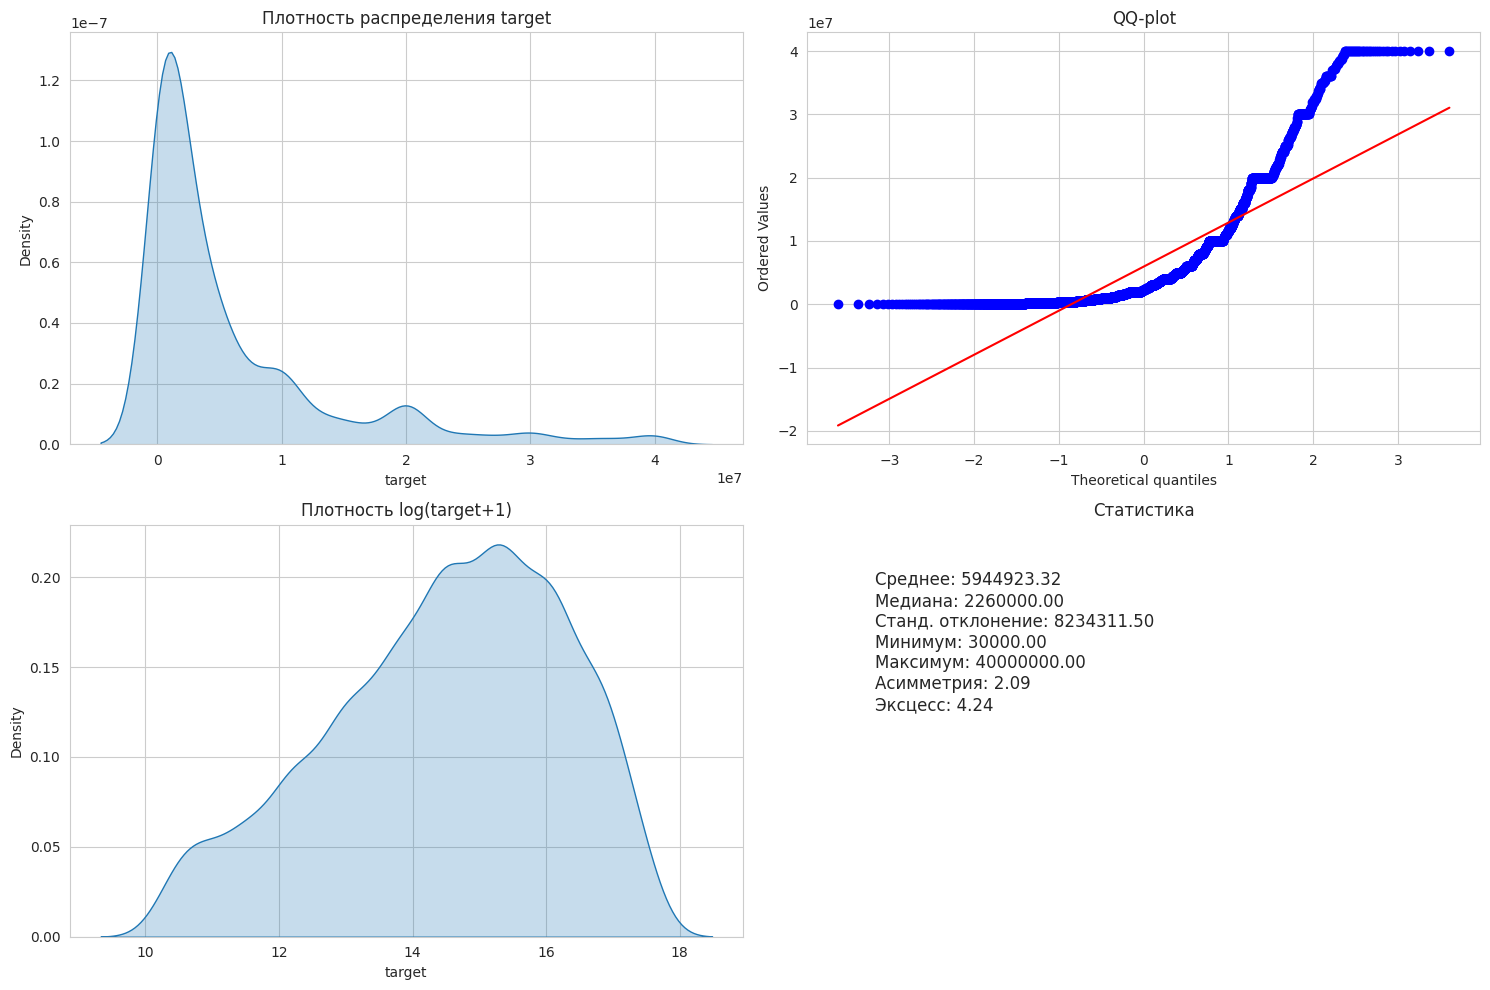

In [23]:
# Статистика target
print("Статистика target:")
print(train_df['target'].describe())
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# KDE plot
sns.kdeplot(train_df['target'], ax=axes[0, 0], fill=True)
axes[0, 0].set_title('Плотность распределения target')

# QQ-plot для проверки нормальности
from scipy import stats
stats.probplot(train_df['target'], dist="norm", plot=axes[0, 1])
axes[0, 1].set_title('QQ-plot')

# Логарифмическое преобразование
sns.kdeplot(np.log1p(train_df['target']), ax=axes[1, 0], fill=True)
axes[1, 0].set_title('Плотность log(target+1)')

# Статистика в виде таблицы
stats_text = f"""
Среднее: {train_df['target'].mean():.2f}
Медиана: {train_df['target'].median():.2f}
Станд. отклонение: {train_df['target'].std():.2f}
Минимум: {train_df['target'].min():.2f}
Максимум: {train_df['target'].max():.2f}
Асимметрия: {train_df['target'].skew():.2f}
Эксцесс: {train_df['target'].kurtosis():.2f}
"""
axes[1, 1].text(0.1, 0.5, stats_text, transform=axes[1, 1].transAxes, fontsize=12)
axes[1, 1].axis('off')
axes[1, 1].set_title('Статистика')

plt.tight_layout()
plt.show()

Среднее больше медианы, большинство значений маленькие в диапазоне от [0; 1]. Есть большая разница между min и max, большой разброс.
Сильный перекос вправо: Большинство значений маленькие (медиана 2.26M), но есть несколько ОЧЕНЬ больших (до 40M), которые тянут среднее вверх.

Эксцесс указывает на тяжелые хвосты, следовательно есть выбросы. Вероятность встретить экстремально большие (или маленькие) значения выше, чем в нормальном распределении.

Признаки выглядят разреженными, очень много значений, которые приближены к нулю.

#### **Удаление константных признаков**

VarienceThreshold - метод удаления низковариативных признаков, который удаляет те признаки, в которых дисперсия не превышает заданного порогового значения. Алгоритм вычисляет дисперсию для каждого признака и сравнивает ее с порогом. Признаки с дисперсией ниже порога - удаляются.

In [24]:
from sklearn.feature_selection import VarianceThreshold

In [25]:
# перед удалением конcтантных признаков, создам отдельную переменную
# Обучаю selector на тренировочных признаках (без ID и target)
X_train = train_df.drop(['ID', 'target'], axis=1)
selector = VarianceThreshold(threshold=0.0)
selector.fit(X_train)

#  Получаю список признаков, которые нужно оставить
selected_cols = X_train.columns[selector.get_support()].tolist()
print(f"Оставляем признаков: {len(selected_cols)}")

# Создаю новые датасеты  с отобранными признаками + ID и target
train_df_clean = train_df[['ID', 'target'] + selected_cols].copy()
test_df_clean = test_df[['ID'] + selected_cols].copy()

print(f"Размер train до: {train_df.shape}, после: {train_df_clean.shape}")
print(f"Размер test до: {test_df.shape}, после: {test_df_clean.shape}")

Оставляем признаков: 4735
Размер train до: (4459, 4993), после: (4459, 4737)
Размер test до: (49342, 4992), после: (49342, 4736)


In [26]:
# так как данных много, то удалять нужно через хеширование
from collections import defaultdict
def find_duplicate_columns_hash(df):
    # Выделяем признаки
    if 'target' in df.columns:
        X = df.drop(['ID', 'target'], axis=1)
    else:
        X = df.drop(['ID'], axis=1)

    # хешируем столбцы
    col_hashes = defaultdict(list)
    for col in X.columns:
        hash_val = hash(tuple(X[col].values))
        col_hashes[hash_val].append(col)

    #  дубликаты
    to_drop = set()
    for hash_val, cols in col_hashes.items():
        if len(cols) > 1:
            to_drop.update(cols[1:])

    print(f"Найдено дублирующихся столбцов: {len(to_drop)}")
    return to_drop

In [27]:
print("Поиск дубликатов через хеширование...")
colsToRemove_hash = find_duplicate_columns_hash(train_df_clean)

Поиск дубликатов через хеширование...
Найдено дублирующихся столбцов: 5


In [28]:
# удаление из обоих датасетов
train_df_clean_no_dups = train_df_clean.drop(colsToRemove_hash, axis=1)
test_df_clean_no_dups = test_df_clean.drop(colsToRemove_hash, axis=1, errors='ignore')

print(f"\nРезультат:")
print(f"Train: {train_df_clean.shape} → {train_df_clean_no_dups.shape}")
print(f"Test: {test_df_clean.shape} → {test_df_clean_no_dups.shape}")


Результат:
Train: (4459, 4737) → (4459, 4732)
Test: (49342, 4736) → (49342, 4731)


In [29]:
# проверка на совпадение колонок
X_train = train_df_clean_no_dups.drop(['ID', 'target'], axis=1)
X_test = test_df_clean_no_dups.drop(['ID'], axis=1)
if list(X_train.columns) == list(X_test.columns):
    print("Все колонки совпадают!")
else:
    print("Колонки не совпадают!")

Все колонки совпадают!


In [30]:
train_df_clean_no_dups.sample(5)

,ID,target,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37,30347e683,d08d1fbe3,6ee66e115,...,3ecc09859,9281abeea,8675bec0b,3a13ed79a,f677d4d13,71b203550,137efaa80,fb36b89d9,7e293fbaf,9fc776466
1206,457945253,4866666.66,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.0,0,0,0,0,0,0,0
2882,a8a0cc490,5937000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.0,0,0,0,0,0,0,0
2823,a5c72ce60,120000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.0,0,0,0,0,0,0,0
4353,f947b4580,56000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,3900000.0,0.0,0,0,0,0,0,0,0
3392,c4611bfb7,2225000.00,0.0,0,0.0,0,0,0,0,0,...,0.0,0.0,0.0,0,0,0,0,0,0,0


In [31]:
test_df_clean_no_dups.sample(5)

,ID,48df886f9,0deb4b6a8,34b15f335,a8cb14b00,2f0771a37,30347e683,d08d1fbe3,6ee66e115,20aa07010,...,3ecc09859,9281abeea,8675bec0b,3a13ed79a,f677d4d13,71b203550,137efaa80,fb36b89d9,7e293fbaf,9fc776466
41601,d8232f04e,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
36846,bf4fa9817,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10715,366d57c12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3889714.28,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
43329,e0a98bb48,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
40237,d1257548b,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### **Feature Engineering**

In [32]:
# копии для feature engineering
X_train_fe = train_df_clean_no_dups.drop(['ID', 'target'], axis=1).copy()
X_test_fe = test_df_clean_no_dups.drop(['ID'], axis=1).copy()

In [33]:
# Сумма всех признаков
X_train_fe['sum_features'] = X_train_fe.sum(axis=1)
X_test_fe['sum_features'] = X_test_fe.sum(axis=1)

# Количество ненулевых признаков
X_train_fe['nonzero_count'] = (X_train_fe > 0).sum(axis=1)
X_test_fe['nonzero_count'] = (X_test_fe > 0).sum(axis=1)

# Максимальное значение
X_train_fe['max_feature'] = X_train_fe.max(axis=1)
X_test_fe['max_feature'] = X_test_fe.max(axis=1)

# Среднее значение ненулевых признаков
def mean_nonzero(row):
    nonzero = row[row > 0]
    return nonzero.mean() if len(nonzero) > 0 else 0

X_train_fe['mean_nonzero'] = X_train_fe.apply(mean_nonzero, axis=1)
X_test_fe['mean_nonzero'] = X_test_fe.apply(mean_nonzero, axis=1)

# Дисперсия признаков
X_train_fe['var_features'] = X_train_fe.var(axis=1)
X_test_fe['var_features'] = X_test_fe.var(axis=1)

print(f"Добавлено 5 новых признаков")
print(f"Train: {X_train_fe.shape}")
print(f"Test: {X_test_fe.shape}")

Добавлено 5 новых признаков
Train: (4459, 4735)
Test: (49342, 4735)


In [34]:
train_df_clean_no_dups = pd.concat([
    train_df_clean_no_dups[['ID', 'target']],
    X_train_fe
], axis=1)

test_df_clean_no_dups = pd.concat([
    test_df_clean_no_dups[['ID']],
    X_test_fe
], axis=1)

print(f"Train после FE: {train_df_clean_no_dups.shape}")
print(f"Test после FE: {test_df_clean_no_dups.shape}")

Train после FE: (4459, 4737)
Test после FE: (49342, 4736)


#### **Отбор признаков через mutual_info_regression (MI)**

Попробую отобрать признаки через функция mutual_info_regression (она используется для оценки взаимной информации между непрерывными признаками и целевой переменной в задачах регрессии.

In [35]:
from sklearn.feature_selection import mutual_info_regression

In [36]:
random.seed(42)

In [37]:
X_train = train_df_clean_no_dups.drop(["ID", "target"], axis=1)
y_train_log = np.log1p(train_df_clean_no_dups["target"].values)
X_test = test_df_clean_no_dups.drop(["ID"], axis=1)

In [38]:
def make_mi_scores(X, y, sample_size=1000, discrete_features='auto'):
    # подвыборка строк
    if len(X) > sample_size:
        indices = np.random.choice(len(X), sample_size, replace=False)
        X_sample = X.iloc[indices]
        y_sample = y[indices] if isinstance(y, np.ndarray) else y.iloc[indices]
        print(f"Используем подвыборку: {sample_size} из {len(X)} строк")
    else:
        X_sample = X
        y_sample = y
        print(f"Используем все {len(X)} строк")

    #  MI на подвыборке
    mi_scores = mutual_info_regression(
        X_sample,
        y_sample,
        discrete_features=discrete_features,
        random_state=42,
        n_neighbors=3
    )
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

print("Расчет Mutual Information на подвыборке...")
mi_scores = make_mi_scores(X_train, y_train_log, sample_size=1000, discrete_features='auto')

Расчет Mutual Information на подвыборке...
Используем подвыборку: 1000 из 4459 строк


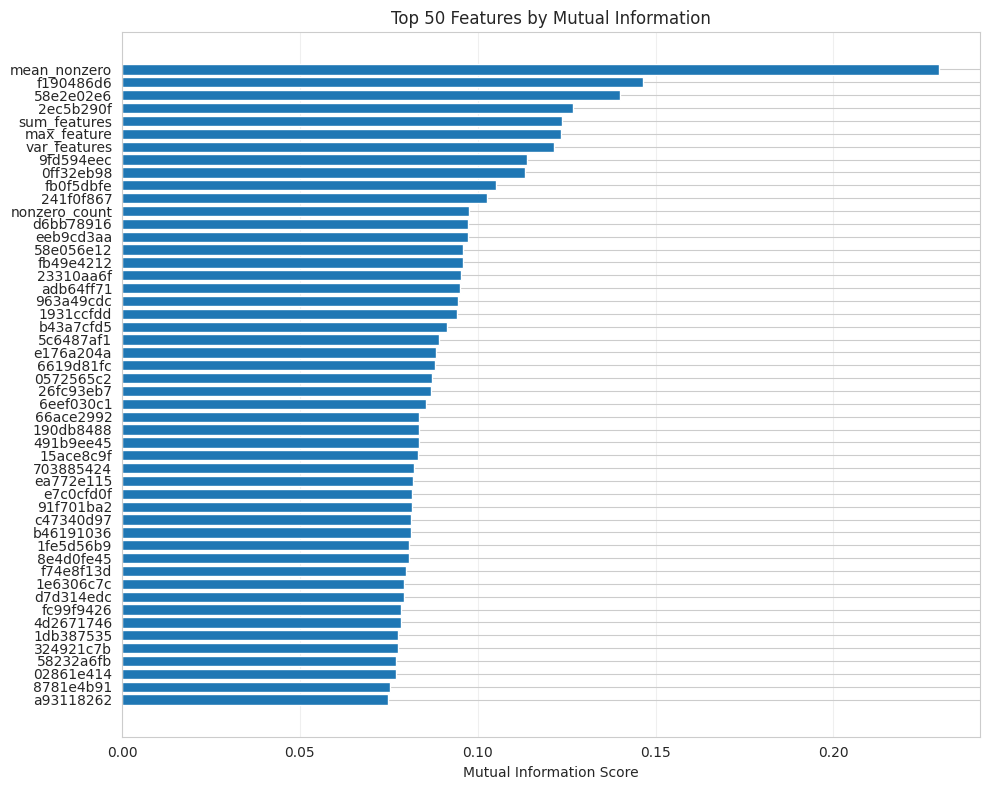

In [39]:
def plot_top_mi_scores(scores, top_n=50):
    # топ-N
    scores_top = scores.head(top_n).sort_values(ascending=True)
    plt.figure(dpi=100, figsize=(10, 8))
    width = np.arange(len(scores_top))
    plt.barh(width, scores_top.values)
    plt.yticks(width, scores_top.index)
    plt.xlabel('Mutual Information Score')
    plt.title(f'Top {top_n} Features by Mutual Information')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
plot_top_mi_scores(mi_scores, top_n=50)

По графику можно сделать следующие выводы:
- во-первых, существует сильный разрыв между первым признаком и всеми остальными
- во-вторых, все признаки плавно убывают
- в-третьих, все признаки имеют значения в пределах от [0; 0.5]

#### **Кросс-валидация**

In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import optuna
from sklearn.metrics import mean_squared_log_error
from IPython.display import display
from sklearn.model_selection import KFold

In [41]:
X_full = train_df_clean_no_dups.drop(["ID", "target"], axis=1)
y_full_log = np.log1p(train_df_clean_no_dups["target"].values)
X_test = test_df_clean_no_dups.drop(["ID"], axis=1)

In [42]:
def objective(trial):

    n_estimators = trial.suggest_int("n_estimators", 100, 500, log=True)
    max_features = trial.suggest_int("max_features", 5, 100)
    max_depth = trial.suggest_int("max_depth", 3, 15)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 15)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 15)
    ccp_alpha = trial.suggest_float("ccp_alpha", 0.0, 0.01)

    model = RandomForestRegressor(
    n_estimators=n_estimators,
    max_depth=max_depth,
    min_samples_split=min_samples_split,
    min_samples_leaf=min_samples_leaf,
    bootstrap=True,
    oob_score=True, # out of bag
    random_state=42,
    n_jobs=-1,
    )
    # K-Fold кросс-валидация (3 фолдов)
    kf = KFold(n_splits=3, shuffle=True, random_state=42)

    # Массив для OOF (Out-of-Fold) предсказаний
    oof_predictions = np.zeros(len(X_full))

    for train_idx, val_idx in kf.split(X_full):
        # Разделяем данные
        X_train_fold = X_full.iloc[train_idx]
        y_train_fold = y_full_log[train_idx]
        X_val_fold = X_full.iloc[val_idx]
        y_val_fold = y_full_log[val_idx]

        # Обучаем модель на фолде
        model.fit(X_train_fold, y_train_fold)

        # Предсказываем на валидационном фолде (OOF)
        y_pred_fold = model.predict(X_val_fold)
        oof_predictions[val_idx] = y_pred_fold

    #  RMSLE на OOF предсказаниях
    y_pred_original = np.expm1(oof_predictions)
    y_true_original = np.expm1(y_full_log)

    rmsle = np.sqrt(mean_squared_log_error(y_true_original, y_pred_original))

    # Сохраняем дополнительную информацию
    trial.set_user_attr('oob_score', model.oob_score_)

    # RMSLE
    return rmsle

In [43]:

study_rf = optuna.create_study(direction="minimize",  study_name="Random_forest_optimization")
study_rf.optimize(objective, n_trials=20, show_progress_bar=True)

[I 2026-10-11 20:29:15,166] A new study created in memory with name: Random_forest_optimization


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-11 20:30:48,889] Trial 0 finished with value: 1.4116489250923807 and parameters: {'n_estimators': 106, 'max_features': 86, 'max_depth': 14, 'min_samples_split': 4, 'min_samples_leaf': 5, 'ccp_alpha': 0.00757599893880826}. Best is trial 0 with value: 1.4116489250923807.
[I 2026-10-11 20:31:59,873] Trial 1 finished with value: 1.4163373249002196 and parameters: {'n_estimators': 108, 'max_features': 15, 'max_depth': 9, 'min_samples_split': 7, 'min_samples_leaf': 8, 'ccp_alpha': 0.003434468792927835}. Best is trial 0 with value: 1.4116489250923807.
[I 2026-10-11 20:36:12,451] Trial 2 finished with value: 1.4099931938618597 and parameters: {'n_estimators': 341, 'max_features': 39, 'max_depth': 12, 'min_samples_split': 5, 'min_samples_leaf': 9, 'ccp_alpha': 0.004766844832045103}. Best is trial 2 with value: 1.4099931938618597.
[I 2026-10-11 20:39:23,886] Trial 3 finished with value: 1.4226197865096801 and parameters: {'n_estimators': 355, 'max_features': 29, 'max_depth': 7, 'min_s

In [44]:
print(f"\nЛучший RMSLE (CV): {study_rf.best_value:.4f}")
print(f"Лучшие параметры:")
for param, value in study_rf.best_params.items():
    print(f"  {param}: {value}")


Лучший RMSLE (CV): 1.4070
Лучшие параметры:
  n_estimators: 481
  max_features: 62
  max_depth: 15
  min_samples_split: 11
  min_samples_leaf: 12
  ccp_alpha: 0.00899109190575337


In [45]:
# OOB score лучшей модели
best_trial = study_rf.best_trial
print(f"OOB Score: {best_trial.user_attrs['oob_score']:.4f}")

OOB Score: 0.3394


In [46]:
# Функция для получения OOF предсказаний с лучшими параметрами
def get_oof_predictions_rf(best_params, X_full, y_full_log, n_splits=3):

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof = np.zeros(len(X_full))
    
    for train_idx, val_idx in kf.split(X_full):
        X_train_fold = X_full.iloc[train_idx]
        y_train_fold = y_full_log[train_idx]
        X_val_fold = X_full.iloc[val_idx]
        
        model = RandomForestRegressor(
            **best_params,
            bootstrap=True,
            oob_score=True,
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_train_fold, y_train_fold)
        oof[val_idx] = model.predict(X_val_fold)
    
    return oof

In [47]:
# OOF для Random Forest
oof_rf = get_oof_predictions_rf(
    study_rf.best_params, 
    X_full, 
    y_full_log
)

print(f"OOF RF shape: {oof_rf.shape}")

OOF RF shape: (4459,)


In [48]:
best_rf = RandomForestRegressor(
    **study_rf.best_params,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
best_rf.fit(X_full, y_full_log)
pred_rf_test = np.expm1(best_rf.predict(X_test))
print(f"RF обучен, test shape: {pred_rf_test.shape}")

RF обучен, test shape: (49342,)


#### **LightGBM**

In [49]:
!pip install lightgbm
import lightgbm as lgb

In [50]:
X_full_lgb = train_df_clean_no_dups.drop(["ID", "target"], axis=1)
y_full_log_lgb = np.log1p(train_df_clean_no_dups["target"].values)
X_test_lgb = test_df_clean_no_dups.drop(["ID"], axis=1)

def objective_lgb(trial):    
    # Гиперпараметры LightGBM
    params = {
        # Основные параметры
        'num_leaves': trial.suggest_int('num_leaves', 10, 80),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 0.8),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 1.0),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        "bagging_freq": trial.suggest_int("bagging_freq", 1, 5),    
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 5, 30),
        
        # L1/L2 регуляризация (аналог ccp_alpha)
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 1.0, log=True),
        
        # Фиксированные параметры
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1,
        'boost_from_average': False  # Важно для RMSLE, чтобы модель не стартовала с нулевого предсказания в логарифмическом пространстве
    }
    
    # Создаем модель
    model = lgb.LGBMRegressor(**params)
    
    # K-Fold кросс-валидация (3 фолдов)
    kf = KFold(n_splits=3, shuffle=True, random_state=42)
    
    # Массив для OOF (Out-of-Fold) предсказаний
    oof_predictions = np.zeros(len(X_full_lgb))
    
    for train_idx, val_idx in kf.split(X_full_lgb):
        # Разделяем данные
        X_train_fold = X_full_lgb.iloc[train_idx]
        y_train_fold = y_full_log_lgb[train_idx]
        X_val_fold =  X_full_lgb.iloc[val_idx]
        y_val_fold = y_full_log_lgb[val_idx]
        
        # модель на фолде
        model.fit(
            X_train_fold, 
            y_train_fold,
            eval_set=[(X_val_fold, y_val_fold)],
            callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)]
        )
        
        # Предсказание на валидационном фолде (OOF),OOF (Out-of-Fold) - это аналог OOB для бустинга
        y_pred_fold = model.predict(X_val_fold, num_iteration=model.best_iteration_)
        oof_predictions[val_idx] = y_pred_fold
    
    # RMSLE на OOF предсказаниях
    y_pred_original = np.expm1(oof_predictions)
    y_true_original = np.expm1(y_full_log_lgb)

    rmsle = np.sqrt(mean_squared_log_error(y_true_original, y_pred_original))
    # У LightGBM нет OOB, но можно сохранить best_iteration
    trial.set_user_attr('best_iteration', model.best_iteration_)
    # RMSLE 
    return rmsle

In [51]:
study_lgb = optuna.create_study(
    direction="minimize",
    study_name="LightGBM_optimization",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_lgb.optimize(objective_lgb, n_trials=20, show_progress_bar=True)

[I 2026-10-11 21:38:47,763] A new study created in memory with name: LightGBM_optimization


  0%|          | 0/20 [00:00<?, ?it/s]

Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's l2: 2.04142
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's l2: 2.01739
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's l2: 1.94593
[I 2026-10-11 21:38:58,213] Trial 0 finished with value: 1.4147749666401412 and parameters: {'num_leaves': 36, 'feature_fraction': 0.7852142919229749, 'bagging_fraction': 0.892797576724562, 'learning_rate': 0.03968793330444373, 'bagging_freq': 1, 'min_data_in_leaf': 9, 'reg_alpha': 0.0014936568554617625, 'reg_lambda': 0.39676050770529875}. Best is trial 0 with value: 1.4147749666401412.
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[52]	valid_0's l2: 2.06382
Training until validation scores don't improve for 50 rounds
Ea

In [52]:
print(f"Лучший RMSLE (CV): {study_lgb.best_value:.4f}")
print(f"\nЛучшие параметры:")
for param, value in study_lgb.best_params.items():
    print(f"  {param}: {value}")

Лучший RMSLE (CV): 1.3922

Лучшие параметры:
  num_leaves: 16
  feature_fraction: 0.5987309519405737
  bagging_fraction: 0.9406069544760228
  learning_rate: 0.07555121409535924
  bagging_freq: 1
  min_data_in_leaf: 13
  reg_alpha: 0.02546477422773794
  reg_lambda: 0.006746944784010361


In [53]:
def get_oof_predictions_lgb(best_params, X_full, y_full_log, n_splits=3):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof = np.zeros(len(X_full))
    
    for train_idx, val_idx in kf.split(X_full):
        X_train_fold = X_full.iloc[train_idx]
        y_train_fold = y_full_log[train_idx]
        X_val_fold = X_full.iloc[val_idx]
        y_val_fold = y_full_log[val_idx]
        
        model = lgb.LGBMRegressor(
            **best_params,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )
        model.fit(
            X_train_fold,
            y_train_fold,
            eval_set=[(X_val_fold, y_val_fold)],
            callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)]
        )
        oof[val_idx] = model.predict(X_val_fold, num_iteration=model.best_iteration_)
    
    return oof

In [54]:
#  OOF для LightGBM
oof_lgb = get_oof_predictions_lgb(
    study_lgb.best_params, 
    X_full_lgb, 
    y_full_log_lgb
)

print(f"OOF LGB shape: {oof_lgb.shape}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[49]	valid_0's l2: 1.9897
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[51]	valid_0's l2: 1.95244
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[76]	valid_0's l2: 1.89391
OOF LGB shape: (4459,)


In [55]:
best_lgb = lgb.LGBMRegressor(
    **study_lgb.best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
best_lgb.fit(X_full_lgb, y_full_log_lgb)
pred_lgb_test = np.expm1(best_lgb.predict(X_test_lgb))
print(f"LGB обучен, test shape: {pred_lgb_test.shape}")

LGB обучен, test shape: (49342,)


**XgBoost**

In [56]:
random.seed(42)
!pip install xgboost
import xgboost as xgb

In [57]:

X_full_xgb = train_df_clean_no_dups.drop(["ID", "target"], axis=1)
y_full_log_xgb = np.log1p(train_df_clean_no_dups["target"].values)
X_test_xgb = test_df_clean_no_dups.drop(["ID"], axis=1)

In [58]:
def objective_xgb(trial):
    
    # Гиперпараметры XGBoost
    params = {
        # Основные параметры
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        
        # Регуляризация (аналог feature_fraction и bagging_fraction)
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.6, 1.0),
        
        # L1/L2 регуляризация (аналог reg_alpha/reg_lambda в LightGBM)
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 1.0, log=True),
        'random_state': 42,
        'n_jobs': -1,
        'verbosity': 0
    }
    
    model = xgb.XGBRegressor(**params)
    
    #  K-Fold кросс-валидация (3 фолдов)
    kf = KFold(n_splits=3, shuffle=True, random_state=48)
    
    # Массив для OOF (Out-of-Fold) предсказаний
    oof_predictions = np.zeros(len(X_full_xgb))
    
    for train_idx, val_idx in kf.split(X_full_xgb):
        X_train_fold = X_full_xgb.iloc[train_idx]
        y_train_fold = y_full_log_xgb[train_idx]
        X_val_fold = X_full_xgb.iloc[val_idx]
        y_val_fold = y_full_log_xgb[val_idx]
        
        # Обучение модель на фолде
        model.fit(
            X_train_fold,
            y_train_fold,
            eval_set=[(X_val_fold, y_val_fold)],
            verbose=False
        )
        
        # Предсказания на валидационном фолде (OOF)
        y_pred_fold = model.predict(X_val_fold)
        oof_predictions[val_idx] = y_pred_fold
    
    # RMSLE на OOF предсказаниях
    y_pred_original = np.expm1(oof_predictions)
    y_true_original = np.expm1(y_full_log_xgb)
    
    rmsle = np.sqrt(mean_squared_log_error(y_true_original, y_pred_original))
    
    trial.set_user_attr('n_estimators_used', params['n_estimators'])
    
    
    return rmsle

In [59]:
study_xgb = optuna.create_study(
    direction="minimize",
    study_name="XGBoost_optimization",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study_xgb.optimize(objective_xgb, n_trials=20, show_progress_bar=True)

[I 2026-10-11 21:42:09,860] A new study created in memory with name: XGBoost_optimization


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-11 21:46:33,860] Trial 0 finished with value: 1.454580987458494 and parameters: {'n_estimators': 437, 'max_depth': 12, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'colsample_bylevel': 0.662397808134481, 'reg_alpha': 0.0014936568554617625, 'reg_lambda': 0.39676050770529875}. Best is trial 0 with value: 1.454580987458494.
[I 2026-10-11 21:56:08,221] Trial 1 finished with value: 1.4080969751333776 and parameters: {'n_estimators': 641, 'max_depth': 10, 'learning_rate': 0.010725209743171997, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9329770563201687, 'colsample_bylevel': 0.6849356442713105, 'reg_alpha': 0.0035113563139704067, 'reg_lambda': 0.0035498788321965025}. Best is trial 1 with value: 1.4080969751333776.
[I 2026-10-11 21:59:12,810] Trial 2 finished with value: 1.4191123180156717 and parameters: {'n_estimators': 374, 'max_depth': 8, 'learning_rate': 0.04345454109729477, 'subsample': 0.716491656079

In [60]:
print(f"Лучший RMSLE (CV): {study_xgb.best_value:.4f}")
print(f"\nЛучшие параметры:")
for param, value in study_xgb.best_params.items():
    print(f"  {param}: {value}")

Лучший RMSLE (CV): 1.3974

Лучшие параметры:
  n_estimators: 557
  max_depth: 8
  learning_rate: 0.015003224144882222
  subsample: 0.7730982444721965
  colsample_bytree: 0.6979002135771539
  colsample_bylevel: 0.9426162727818553
  reg_alpha: 0.44848034171104684
  reg_lambda: 0.005176414021223836


In [61]:
def get_oof_predictions_xgb(best_params, X_full, y_full_log, n_splits=3):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    oof = np.zeros(len(X_full))
    
    for train_idx, val_idx in kf.split(X_full):
        X_train_fold = X_full.iloc[train_idx]
        y_train_fold = y_full_log[train_idx]
        X_val_fold = X_full.iloc[val_idx]
        
        model = xgb.XGBRegressor(
            **best_params,
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )
        model.fit(X_train_fold, y_train_fold, verbose=False)
        oof[val_idx] = model.predict(X_val_fold)
    
    return oof

In [62]:
# OOF для XGBoost
oof_xgb = get_oof_predictions_xgb(
    study_xgb.best_params, 
    X_full_xgb, 
    y_full_log_xgb
)

print(f"OOF XGB shape: {oof_xgb.shape}")

OOF XGB shape: (4459,)


In [63]:
best_xgb = xgb.XGBRegressor(
    **study_xgb.best_params,
    random_state=48,
    n_jobs=-1,
    verbosity=0
)
best_xgb.fit(X_full_xgb, y_full_log_xgb)
pred_xgb_test = np.expm1(best_xgb.predict(X_test_xgb))
print(f"XGB обучен, test shape: {pred_xgb_test.shape}")

XGB обучен, test shape: (49342,)


Получить тестовые предсказания от всех моделей

In [64]:
# Для Random Forest (X_full, y_full_log, X_test)
best_rf = RandomForestRegressor(
    **study_rf.best_params,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
best_rf.fit(X_full, y_full_log)
pred_rf_test = np.expm1(best_rf.predict(X_test))

# LightGBM (best_lgb)
pred_lgb_test = np.expm1(best_lgb.predict(X_test_lgb))

# XGBoost (best_xgb)
pred_xgb_test = np.expm1(best_xgb.predict(X_test_xgb))

print(f"RF test shape: {pred_rf_test.shape}")
print(f"LGB test shape: {pred_lgb_test.shape}")
print(f"XGB test shape: {pred_xgb_test.shape}")

RF test shape: (49342,)
LGB test shape: (49342,)
XGB test shape: (49342,)


Блендинг (Blending) - это метод ансамблирования, при котором усредняются предсказания нескольких моделей с определенными весами.

In [65]:
from scipy.optimize import minimize
from sklearn.metrics import mean_squared_log_error

In [66]:
def blend_loss(weights, oof_preds, y_true):
    pred_blend = np.sum(oof_preds * weights, axis=1)
    return np.sqrt(mean_squared_log_error(np.expm1(y_true), np.expm1(pred_blend)))

oof_preds = np.column_stack([oof_rf, oof_lgb, oof_xgb])
init_weights = [1/3, 1/3, 1/3]
bounds = [(0, 1)] * 3
constraint = {'type': 'eq', 'fun': lambda w: sum(w) - 1}

result = minimize(lambda w: blend_loss(w, oof_preds, y_full_log), 
                 init_weights, method='SLSQP', bounds=bounds, constraints=constraint)
optimal_weights = result.x

print("\nОптимальные веса:")
print(f"  Random Forest: {optimal_weights[0]:.4f}")
print(f"  LightGBM:      {optimal_weights[1]:.4f}")
print(f"  XGBoost:       {optimal_weights[2]:.4f}")


Оптимальные веса:
  Random Forest: 0.0016
  LightGBM:      0.4536
  XGBoost:       0.5448


In [67]:
# финальный блендинг
preds_test = np.column_stack([pred_rf_test, pred_lgb_test, pred_xgb_test])
pred_blend = np.sum(preds_test * optimal_weights, axis=1)

submission_blend = pd.DataFrame({
    'ID': test_df_clean_no_dups['ID'],
    'target': pred_blend
})
submission_blend.to_csv('submission_blend.csv', index=False)
print("Сабмит блендинга сохранен!")

Сабмит блендинга сохранен!


In [68]:
# OOF RMSLE для каждой модели
rf_oof_rmsle = study_rf.best_value
lgb_oof_rmsle = study_lgb.best_value
xgb_oof_rmsle = study_xgb.best_value

# OOB Score (только для Random Forest)
best_trial_rf = study_rf.best_trial
rf_oob = best_trial_rf.user_attrs.get('oob_score', 'N/A')

# Best Iteration (только для LightGBM)
best_trial_lgb = study_lgb.best_trial
lgb_best_iter = best_trial_lgb.user_attrs.get('best_iteration', 'N/A')

In [69]:
# RMSLE блендинга на OOF
pred_blend_oof = np.sum(oof_preds * optimal_weights, axis=1)
blend_rmsle = np.sqrt(mean_squared_log_error(
    np.expm1(y_full_log), 
    np.expm1(pred_blend_oof)
))

In [70]:
models_comparison = pd.DataFrame({
    'Модель': ['Random Forest', 'LightGBM', 'XGBoost', 'Blending (Ensemble)'],
    'OOF RMSLE': [
        rf_oof_rmsle,
        lgb_oof_rmsle,
        xgb_oof_rmsle,
        blend_rmsle
    ],
    'OOB Score': [
        rf_oob,
        '—',
        '—',
        '—'
    ],
    'Best Iteration': [
        '—',
        lgb_best_iter,
        '—',
        '—'
    ],
    'Улучшение vs Best': [
        f"{(min(lgb_oof_rmsle, xgb_oof_rmsle, rf_oof_rmsle) - rf_oof_rmsle):.4f}",
        f"{(min(lgb_oof_rmsle, xgb_oof_rmsle, rf_oof_rmsle) - lgb_oof_rmsle):.4f}",
        f"{(min(lgb_oof_rmsle, xgb_oof_rmsle, rf_oof_rmsle) - xgb_oof_rmsle):.4f}",
        f"{(min(lgb_oof_rmsle, xgb_oof_rmsle, rf_oof_rmsle) - blend_rmsle):.4f}"
    ]
})

# Сортируем по RMSLE
models_comparison = models_comparison.sort_values('OOF RMSLE')

print("="*70)
print("ТАБЛИЦА 1: СРАВНЕНИЕ МОДЕЛЕЙ")
print("="*70)
display(models_comparison)

ТАБЛИЦА 1: СРАВНЕНИЕ МОДЕЛЕЙ


,Модель,OOF RMSLE,OOB Score,Best Iteration,Улучшение vs Best
3,Blending (Ensemble),1.385756,—,—,0.0064
1,LightGBM,1.392167,—,74,0.0000
2,XGBoost,1.397436,—,—,-0.0053
0,Random Forest,1.407035,0.339391,—,-0.0149


In [71]:
best_model = models_comparison.iloc[0]['Модель']
best_rmsle = models_comparison.iloc[0]['OOF RMSLE']
improvement = min(rf_oof_rmsle, lgb_oof_rmsle, xgb_oof_rmsle) - blend_rmsle

summary_df = pd.DataFrame({
    'Показатель': [
        'Лучшая модель',
        'Лучший OOF RMSLE',
        'Улучшение от блендинга',
        'Количество признаков',
        'Количество строк (train)',
        'Размер тестовой выборки'
    ],
    'Значение': [
        best_model,
        f"{best_rmsle:.4f}",
        f"{improvement:.4f} ({improvement/best_rmsle*100:.2f}%)",
        f"{X_full.shape[1]}",
        f"{len(X_full)}",
        f"{len(X_test)}"
    ]
})

print("\n" + "="*40)
print("ТАБЛИЦА 4: ИТОГОВАЯ СВОДКА")
print("="*40)
display(summary_df)


ТАБЛИЦА 4: ИТОГОВАЯ СВОДКА


,Показатель,Значение
0,Лучшая модель,Blending (Ensemble)
1,Лучший OOF RMSLE,1.3858
2,Улучшение от блендинга,0.0064 (0.46%)
3,Количество признаков,4735
4,Количество строк (train),4459
5,Размер тестовой выборки,49342
